# Feature Extraction with Pretrained Model 

This Jupyter Notebook contains an image recognition model that uses feature maps that are extracted using a pretrained `VGG16` model instead of original images for training and prediction making. The model is trained to recognize four different types of dinnerware items from images. The model is created using the `Keras` library with `TesnsorFlow` as the backend. 

`Matplotlib.pyplot` and `NumPy` libraries are used for formatting and visualising data and performance results. `Time` library provides a method for measuring the model's training time. The `Scikit Learn` library is used to calculate performance metrics and also to display them more visually.

In [1]:
import os, shutil, pathlib
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
import time
import random

keras.utils.set_random_seed(2)

C:\Users\riikk\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Using the `keras.utils.set_random_seed` function reduces the difference between different runs so that performance results are more similar if the model is created and trained again. 

## Data Preprocessing

The dataset used for the training contains images of four different types of dinnerware items: bowls, drinking glasses, mugs and plates. The images were preprocessed using Python wiht function from the `Pillow (PIL)` library. The images were cropped, resized, converted to RGB and renamed with code. For a more detailed description of the dataset refer to the `Assignment2_raport.ipynb` notebook.

The dataset is fetched from the base folder using the `pathlib.Path` class and Keras library's `image_dataset_from_directory` function. For the function to work correctly the dinnerware images need to be divided in their own folders with aproriate class names. The function is used three times to get subsets for training, validation and testing. The `batch_size` is 32 and `image_size` is 224x224 pixels. The `seed` parameter ensures that the initial shuffle of the datasets is always the same increasing reproducbility.

In [2]:
base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=True,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)

for data_batch, labels_batch in train_dataset:
    print("Data batch shape:", data_batch.shape)
    print("Labels batch shape:", labels_batch.shape)
    break

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.
Data batch shape: (32, 224, 224, 3)
Labels batch shape: (32,)


The training set has 296 images, the validation set has 93 images and the test set has 95 images. A batch has 32 images wiht 224 x 224 dimension and they are RGB colour images that contain three colour channels. This explains the batch shape: (32, 224, 224, 3).

Below are some examples of the images in the training dataset with their labels or class names.

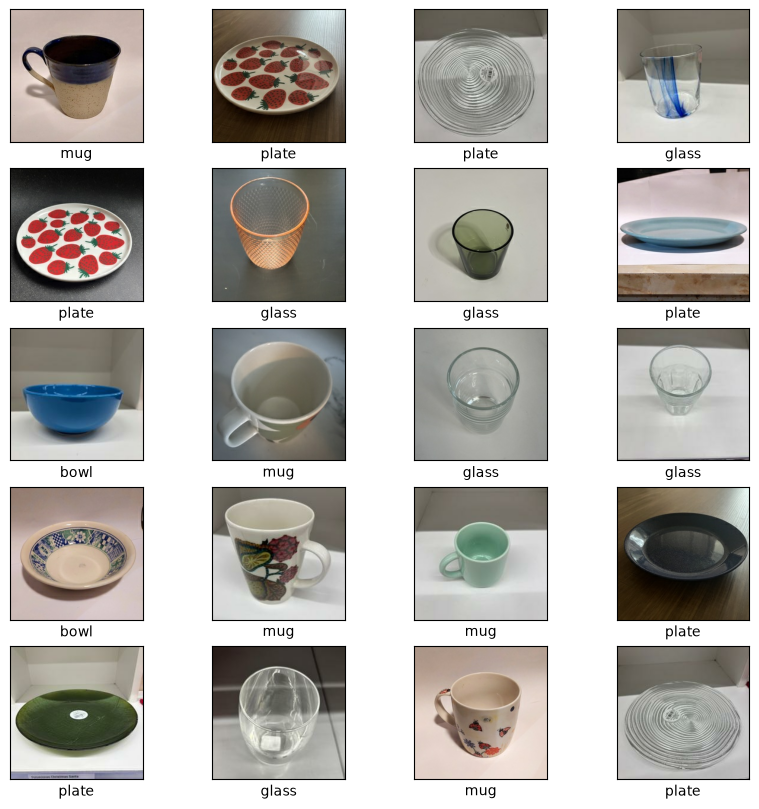

In [121]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

## Feature Extraction

In [122]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3))
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_22 (InputLayer)          │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [123]:
def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images)
        features = conv_base.predict(preprocessed_images)
        all_features.append(features)
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)

train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

train_features.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


(296, 7, 7, 512)

In [124]:
np.random.seed(2)
random.seed(2)

inputs = keras.Input(shape=(7, 7, 512))
x = layers.GlobalAveragePooling2D()(inputs) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_23 (InputLayer)          │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_63 (Dense)                     │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_32 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_64 (Dense)                     │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_33 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_65 (Dense)                     │ (None, 4)                   │             260 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 148,036 (578.27 KB)

 Trainable params: 148,036 (578.27 KB)

 Non-trainable params: 0 (0.00 B)

In [125]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [126]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction.keras",
        save_best_only=True,
        monitor="val_accuracy"),
        keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=10, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_features, train_labels,
    epochs=50,
    validation_data=(val_features, val_labels),
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.3581 - loss: 2.7110 - val_accuracy: 0.8280 - val_loss: 0.4821
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6892 - loss: 0.9986 - val_accuracy: 0.8710 - val_loss: 0.4035
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7500 - loss: 0.7340 - val_accuracy: 0.8925 - val_loss: 0.3320
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8108 - loss: 0.5421 - val_accuracy: 0.8387 - val_loss: 0.3672
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8682 - loss: 0.3477 - val_accuracy: 0.8602 - val_loss: 0.3029
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9257 - loss: 0.2296 - val_accuracy: 0.8602 - val_loss: 0.3095
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9122 - loss: 0.2005 - val_accuracy: 0.8495 - val_loss: 0.3586
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9155 - loss: 0.2217 - val_accuracy: 0.8710 - v

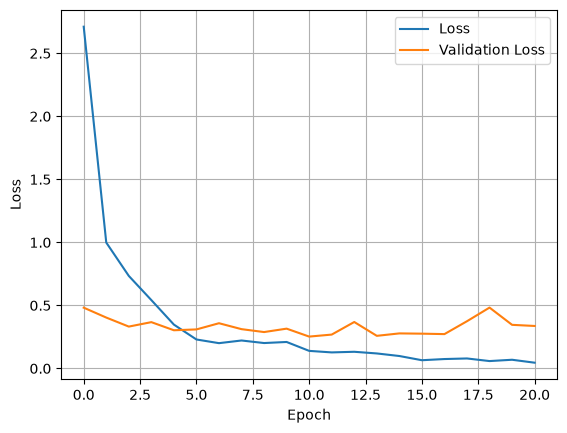

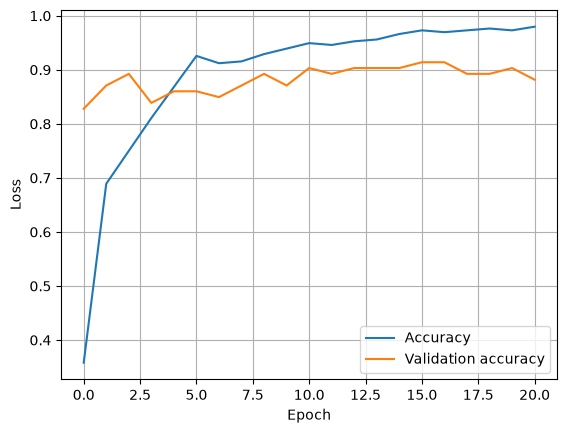

In [127]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

In [128]:
test_model = keras.models.load_model("feature_extraction.keras")
test_loss, test_acc = test_model.evaluate(test_features, test_labels)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8947 - loss: 0.3513 
Test accuracy: 0.895
Test loss: 0.351


In [129]:
probs = test_model.predict(test_features)
y_pred = np.argmax(probs, axis=1)
y_true = test_labels

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
              precision    recall  f1-score   support

        bowl       0.95      0.81      0.88        26
       glass       0.83      1.00      0.91        24
         mug       0.85      0.81      0.83        21
       plate       0.96      0.96      0.96        24

    accuracy                           0.89        95
   macro avg       0.90      0.89      0.89        95
weighted avg       0.90      0.89      0.89        95



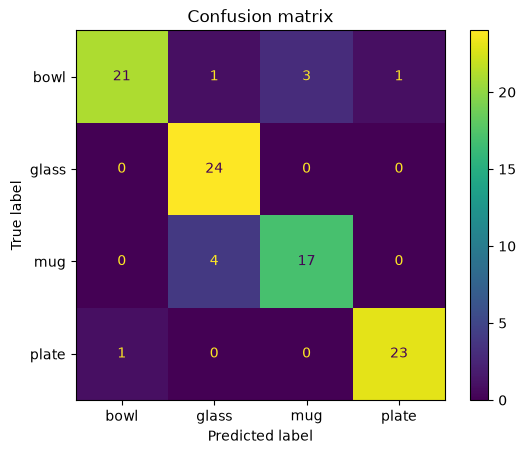

In [130]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

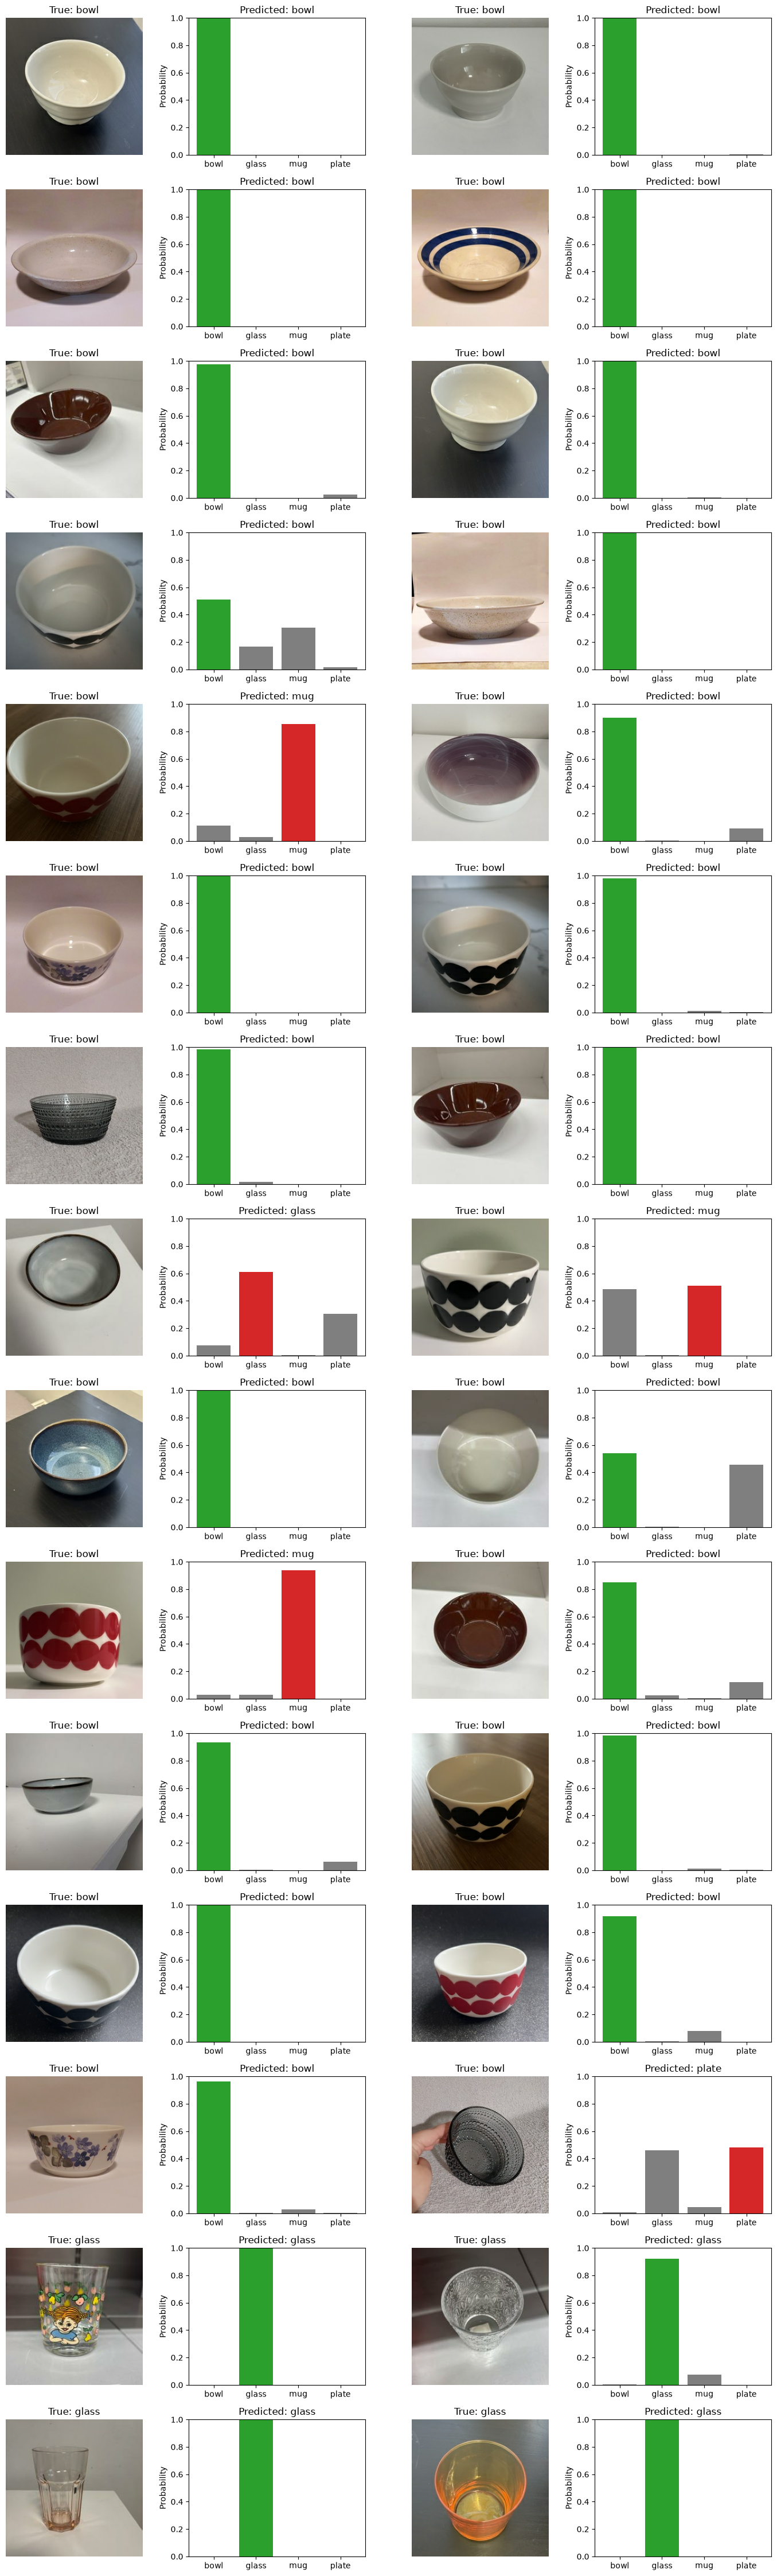

In [131]:
x, y = next(iter(test_dataset))

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

| Test            | Modification                                                                | Accuracy (%) | Test loss |  Training time (top layers) (s) | Conclusions          |
| --------------- | --------------------------------------------------------------------------- | ------------ | --------- | ------------------------------- | -------------------- |
| Original model  |                                                                             | 86.3         | 0.422     | 3.8                | Test accuracy is already better than with the CNN model. Test loss is not great but it is not too bad either. The validation accuracy and loss scores seem to stabilize quite fast meaning that the model does not learn much more after the first five epochs or so. |
| Version 1       | Added Dense(32) layer                                                       | 84.2         | 0.486     | 4.5                | Test accuracy and loss scores are worse. The validation accuracy scores seem to not getter much better after the firts five epochs. The validation loss scores seem to get worse at later epochs which could indicate overfitting.  |
| Original model  | Remove Dense(32) layer, and set learning rate to 0.001                      | 86.3         | 0.422     | 3.6                | No noticeable difference when compared to the first test.|
| Version 3       | Split Dense(156) layer into smaller layers, change GlobalAveragePooling2D layer into Flatten(), update and add Dropout() layers| 89.5        | 0.515     | 16.2    | Test accuracy score is slightly better but the test loss score is worse. The validation and accuracy scores seem to still stabilize quickly meaning that the model struggles to learn. Training time is longer.   |
| Version 4       | Add Dropout(0.15) layer                                                     | 86.3         | 0.636     | 12.6               | Test accuracy score is not better than with the original version even though the validation accuracy scores were promising.          |
| Version 5       | Simplify model                                                              | 88.4         | 0.830     | 8.6                | Test accuracy is slightly better but test loss score is much worse compared to the original model. Validation loss scores do not improve after the start of the training and accuracy scores fluctuate a lot.              |
| Version 6       | Add a Dropout() layer                                                       | 90.5         | 0.760     | 13.6               | Test accuracy score is the highest of all the tests. Test loss score is noticeably worse compared to the original. The validation accuracy and loss scores do improve during the training though they fluctuate a lot.               |

**Original model**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.GlobalAveragePooling2D()(inputs) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 2**<br>
**Added Dense(32) layer**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.GlobalAveragePooling2D()(inputs) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 3**<br>
**Split Dense(256), change to Flatten(), Dropout(0.2) and Dropout(0.1)**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 4**<br>
**Added Dropout(0.15) layer**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.15)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 5**<br>
**Simplify model (remove layers)**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

**Version 6**<br>
**Add Dense(16) layer**

```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.Flatten()(inputs) 
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(16, activation="relu")(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```

Tämä antaa accuracy 92% kun train datasetissa ei ole shuffle päällä

**Final Version**</br>
```python
inputs = keras.Input(shape=(7, 7, 512))
x = layers.GlobalAveragePooling2D()(inputs) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs)
```